In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
courses = pd.read_csv("Course_Completion_Prediction.csv")

In [3]:
# Loading the dataset
courses.head()

,Student_ID,Name,Gender,Age,Education_Level,Employment_Status,City,Device_Type,Internet_Connection_Quality,Course_ID,...,Enrollment_Date,Payment_Mode,Fee_Paid,Discount_Used,Payment_Amount,App_Usage_Percentage,Reminder_Emails_Clicked,Support_Tickets_Raised,Satisfaction_Rating,Completed
0,STU100000,Vihaan Patel,Male,19,Diploma,Student,Indore,Laptop,Medium,C102,...,01-06-2024,Scholarship,No,No,1740,49,3,4,3.5,Completed
1,STU100001,Arjun Nair,Female,17,Bachelor,Student,Delhi,Laptop,Low,C106,...,27-04-2025,Credit Card,Yes,No,6147,86,0,0,4.5,Not Completed
2,STU100002,Aditya Bhardwaj,Female,34,Master,Student,Chennai,Mobile,Medium,C101,...,20-01-2024,NetBanking,Yes,No,4280,85,1,0,5.0,Completed
3,STU100003,Krishna Singh,Female,29,Diploma,Employed,Surat,Mobile,High,C105,...,13-05-2025,UPI,Yes,No,3812,42,2,3,3.8,Completed
4,STU100004,Krishna Nair,Female,19,Master,Self-Employed,Lucknow,Laptop,Medium,C106,...,19-12-2024,Debit Card,Yes,Yes,5486,91,3,0,4.0,Completed


In [4]:
# Quick Summary Statistics
courses.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 40 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Student_ID                    100000 non-null  str    
 1   Name                          100000 non-null  str    
 2   Gender                        100000 non-null  str    
 3   Age                           100000 non-null  int64  
 4   Education_Level               100000 non-null  str    
 5   Employment_Status             100000 non-null  str    
 6   City                          100000 non-null  str    
 7   Device_Type                   100000 non-null  str    
 8   Internet_Connection_Quality   100000 non-null  str    
 9   Course_ID                     100000 non-null  str    
 10  Course_Name                   100000 non-null  str    
 11  Category                      100000 non-null  str    
 12  Course_Level                  100000 non-null  str    
 

In [5]:
# Checking for null values
courses.isnull().sum()

Student_ID                      0
Name                            0
Gender                          0
Age                             0
Education_Level                 0
Employment_Status               0
City                            0
Device_Type                     0
Internet_Connection_Quality     0
Course_ID                       0
Course_Name                     0
Category                        0
Course_Level                    0
Course_Duration_Days            0
Instructor_Rating               0
Login_Frequency                 0
Average_Session_Duration_Min    0
Video_Completion_Rate           0
Discussion_Participation        0
Time_Spent_Hours                0
Days_Since_Last_Login           0
Notifications_Checked           0
Peer_Interaction_Score          0
Assignments_Submitted           0
Assignments_Missed              0
Quiz_Attempts                   0
Quiz_Score_Avg                  0
Project_Grade                   0
Progress_Percentage             0
Rewatch_Count 

In [6]:
# Checking for duplicate values
courses.duplicated().sum()

np.int64(0)

The dataset has no null or duplicate values.

In [7]:
# Checking the correlation of the numeric features

correlation_matrix = courses.corr(numeric_only=True).round(2)

correlation_matrix

,Age,Course_Duration_Days,Instructor_Rating,Login_Frequency,Average_Session_Duration_Min,Video_Completion_Rate,Discussion_Participation,Time_Spent_Hours,Days_Since_Last_Login,Notifications_Checked,...,Quiz_Attempts,Quiz_Score_Avg,Project_Grade,Progress_Percentage,Rewatch_Count,Payment_Amount,App_Usage_Percentage,Reminder_Emails_Clicked,Support_Tickets_Raised,Satisfaction_Rating
Age,1.00,-0.00,-0.00,-0.00,-0.00,-0.00,0.01,-0.00,-0.00,-0.01,...,-0.00,0.00,0.00,0.00,-0.00,-0.00,-0.00,0.00,0.00,-0.00
Course_Duration_Days,-0.00,1.00,0.64,0.01,0.00,-0.00,0.00,0.00,-0.00,0.00,...,-0.00,0.01,0.00,0.00,-0.00,0.35,0.00,0.00,-0.00,0.00
Instructor_Rating,-0.00,0.64,1.00,-0.00,0.00,-0.00,0.00,0.00,-0.00,0.00,...,0.00,0.01,0.00,-0.00,-0.00,0.22,0.00,0.00,-0.00,0.00
Login_Frequency,-0.00,0.01,-0.00,1.00,0.08,0.05,0.08,0.20,-0.06,0.09,...,0.09,0.10,0.08,0.12,0.08,0.00,0.04,0.08,-0.06,0.05
Average_Session_Duration_Min,-0.00,0.00,0.00,0.08,1.00,0.04,0.08,0.16,-0.04,0.08,...,0.08,0.09,0.07,0.10,0.07,-0.00,0.04,0.07,-0.05,0.04
Video_Completion_Rate,-0.00,-0.00,-0.00,0.05,0.04,1.00,0.04,0.01,-0.02,0.05,...,0.04,0.05,0.04,0.59,0.04,-0.00,0.02,0.04,-0.03,0.02
Discussion_Participation,0.01,0.00,0.00,0.08,0.08,0.04,1.00,0.03,-0.04,0.08,...,0.08,0.09,0.08,0.10,0.07,-0.00,0.03,0.08,-0.05,0.04
Time_Spent_Hours,-0.00,0.00,0.00,0.20,0.16,0.01,0.03,1.00,-0.01,0.03,...,0.03,0.03,0.03,0.03,0.03,-0.01,0.01,0.03,-0.02,0.01
Days_Since_Last_Login,-0.00,-0.00,-0.00,-0.06,-0.04,-0.02,-0.04,-0.01,1.00,-0.05,...,-0.04,-0.06,-0.04,-0.06,-0.04,0.00,-0.02,-0.04,0.03,-0.03
Notifications_Checked,-0.01,0.00,0.00,0.09,0.08,0.05,0.08,0.03,-0.05,1.00,...,0.08,0.10,0.08,0.11,0.08,-0.00,0.04,0.08,-0.05,0.05


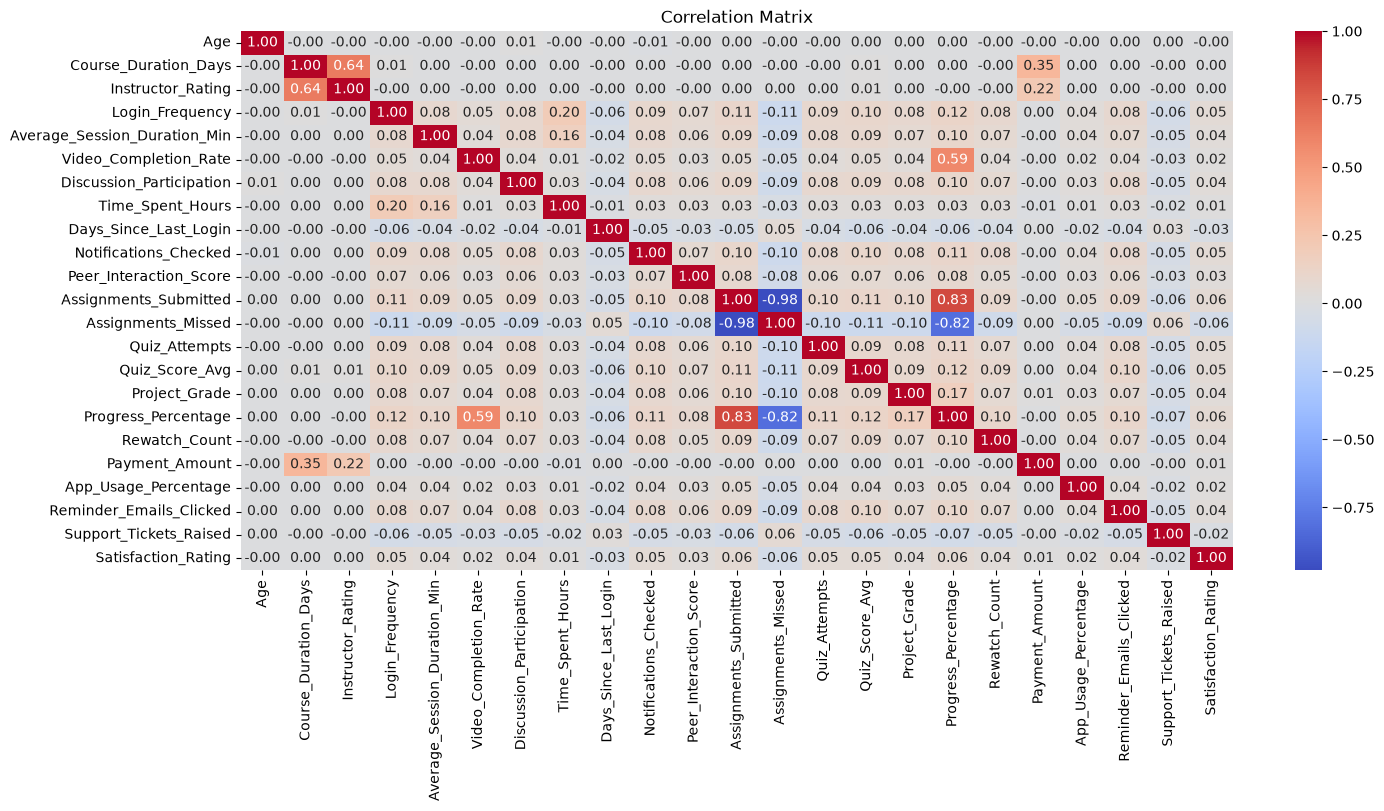

In [8]:
plt.figure(figsize=(16, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

**Age** has a very weak to no correlation with any of the feautures.

**Course_Duration_Days** has weak to no correlation with most features but approx. 35% corr with **payment amount** and 64% corr with **course duration days**.

**Login_Frewuency** has weak positive corr with time spent in hours (20%)

**Average_Session_Duration** has weak positive correlation with **Time_spent_Hours** (16%)

**Video_Completion_Rate** has a strong positive corr with **Progress_Percentage** at 59%

**Assignments_Submitted** has a strong positive correlation with **Progress_Percentage** at 83% and a strong negative correlation with **Assignments_Missed** at -98%

**Assignments_Missed** has a strong negative correlation with both **Progress_Percentage** and **Assignments_Submitted** at -82% and -98% respectively.

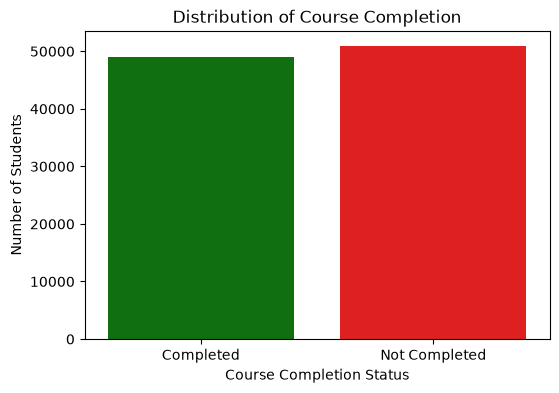

In [9]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=courses,
    x='Completed',
    hue='Completed',
    legend=False,
    palette={
        'Completed': 'green',
        'Not Completed': 'red'
    }
)

plt.title('Distribution of Course Completion')
plt.xlabel('Course Completion Status')
plt.ylabel('Number of Students')

plt.show()

The distribution of the dataset is that there are more students who do not complete the courses they have signed up for. As much as the margin is small, how can we encourage more students to complete their online courses based on the features?

## Exploratory Data Analysis
1. Univariate Analysis
    - Numerical Features

In [10]:
# Identifying the numerical columns in the dataset
numerical_cols = courses.select_dtypes(include=['int64', 'float64']).columns
print(numerical_cols)

Index(['Age', 'Course_Duration_Days', 'Instructor_Rating', 'Login_Frequency',
       'Average_Session_Duration_Min', 'Video_Completion_Rate',
       'Discussion_Participation', 'Time_Spent_Hours', 'Days_Since_Last_Login',
       'Notifications_Checked', 'Peer_Interaction_Score',
       'Assignments_Submitted', 'Assignments_Missed', 'Quiz_Attempts',
       'Quiz_Score_Avg', 'Project_Grade', 'Progress_Percentage',
       'Rewatch_Count', 'Payment_Amount', 'App_Usage_Percentage',
       'Reminder_Emails_Clicked', 'Support_Tickets_Raised',
       'Satisfaction_Rating'],
      dtype='str')


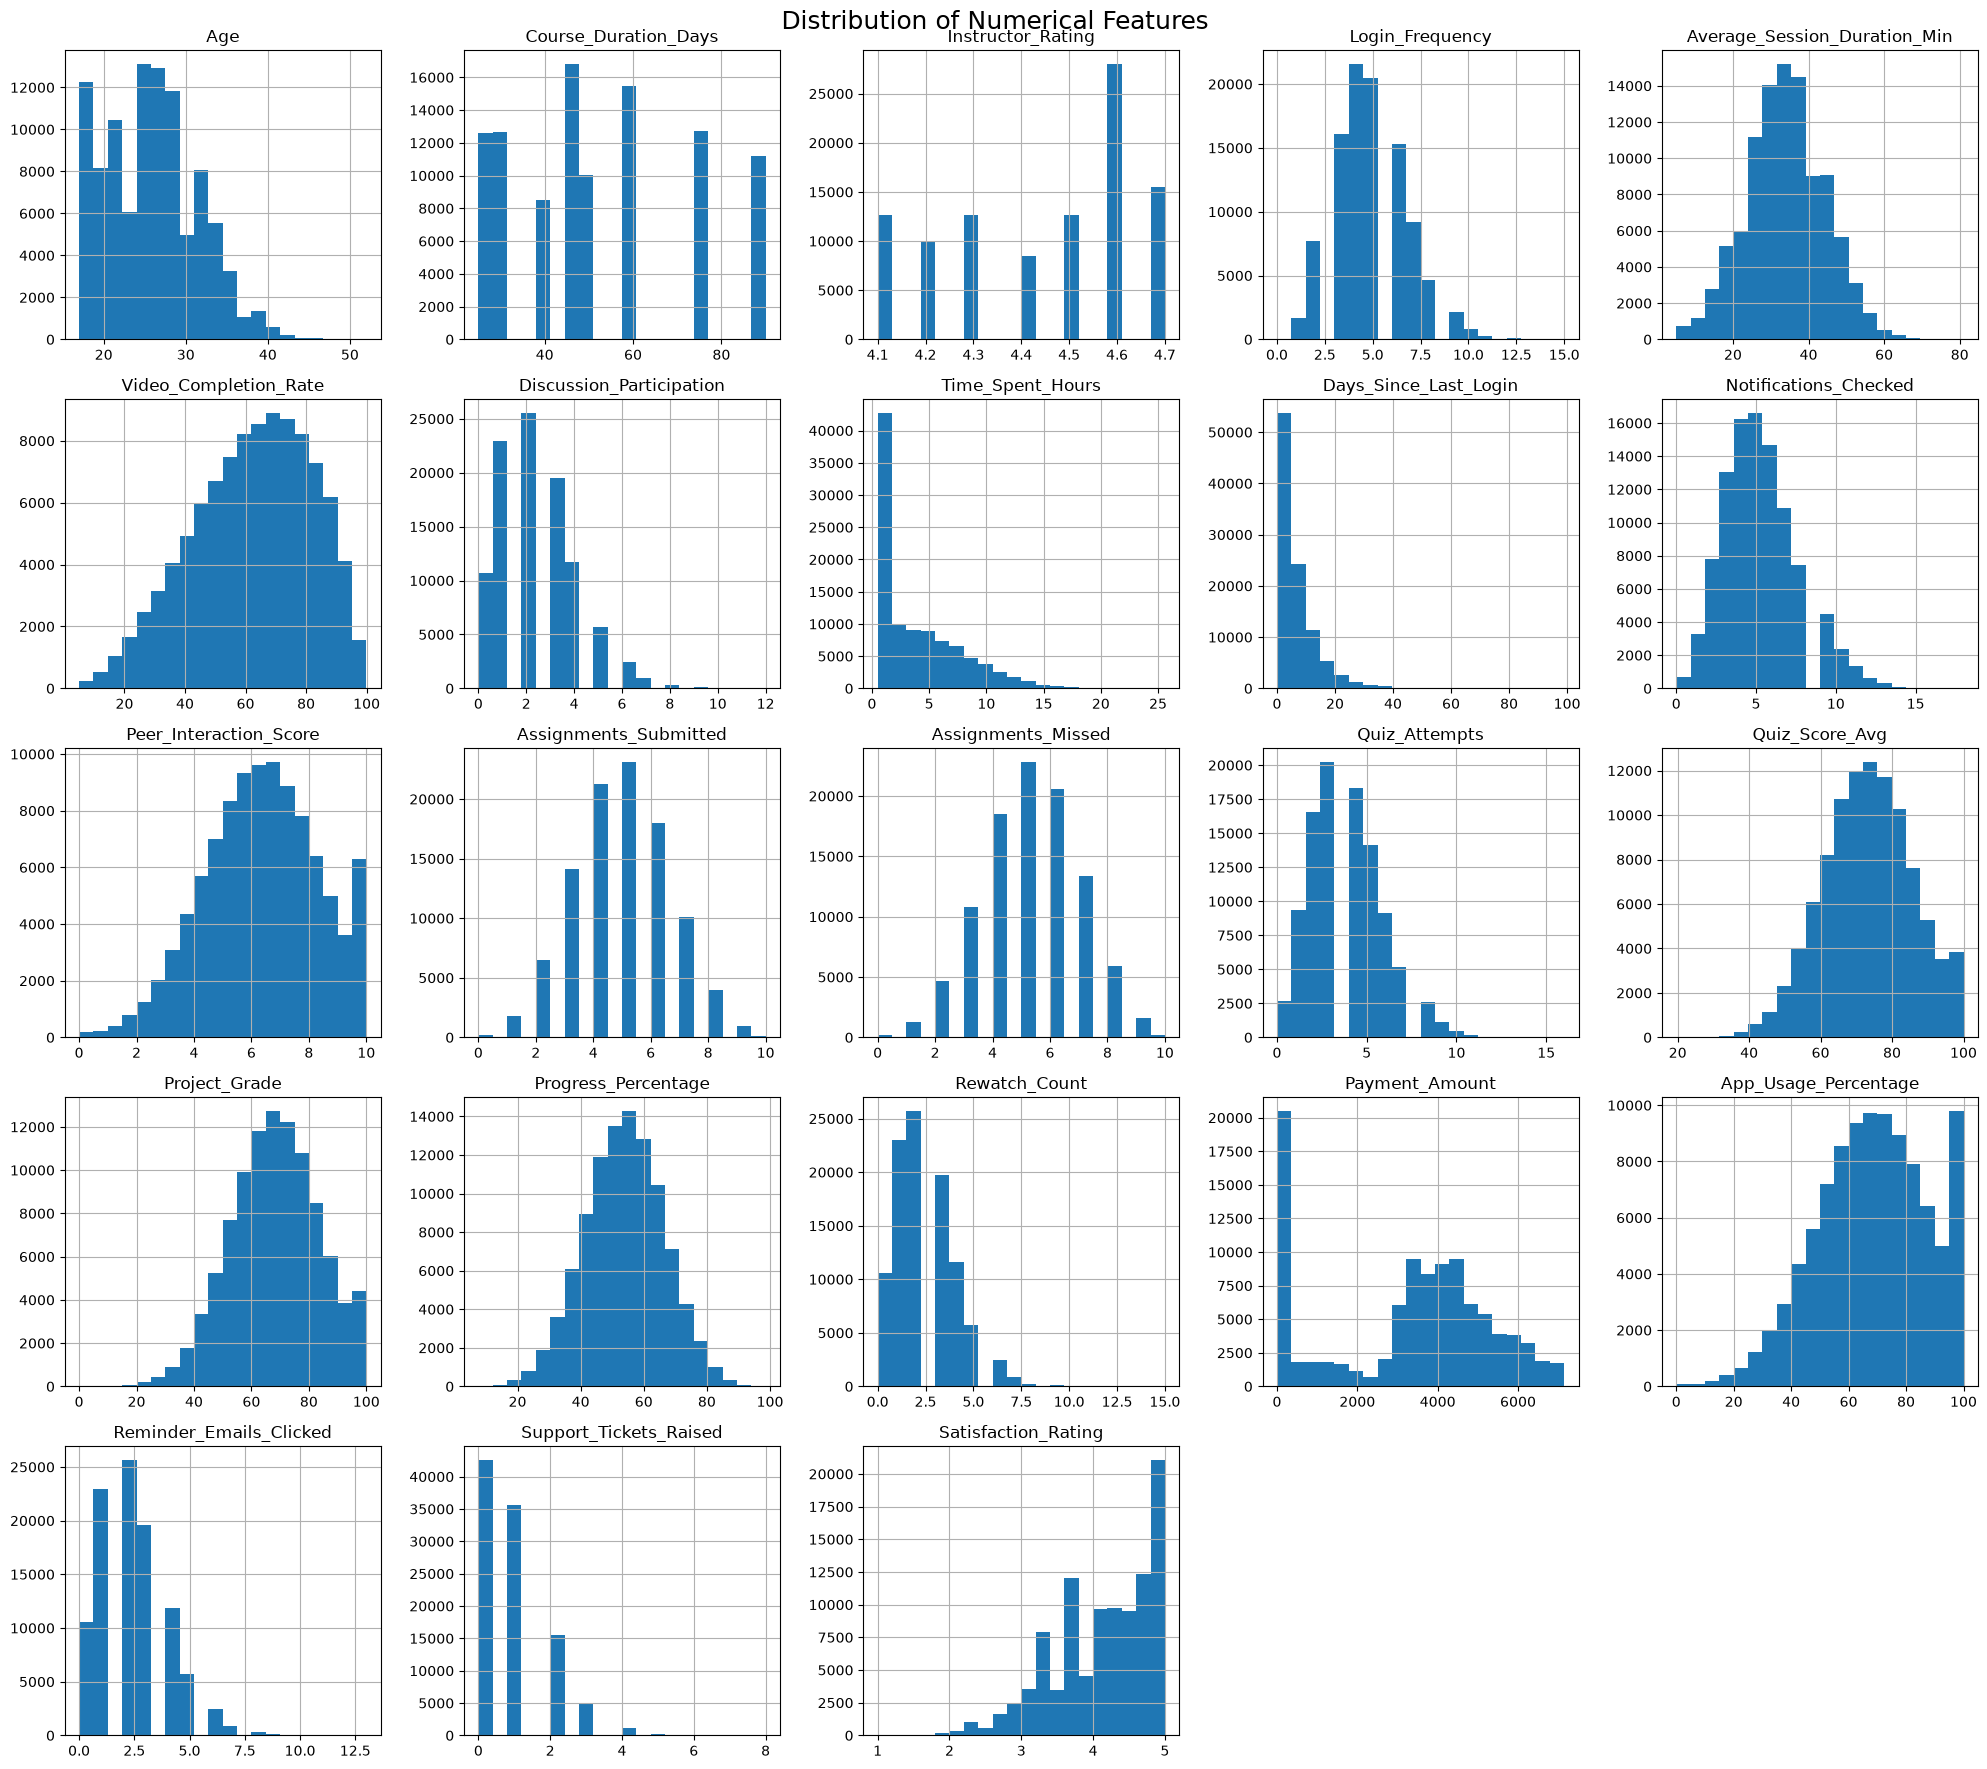

In [11]:
# Plotting their distribution
courses[numerical_cols].hist(figsize=(20,18), bins=20)

plt.suptitle("Distribution of Numerical Features", fontsize=18)
plt.tight_layout()

plt.show()

The numerical features show a mixture of approximately normal and skewed distributions. Features related to performance metrics, such as quiz scores, project grades, and progress percentage, display near-normal distributions. However, engagement-related features such as time spent, login inactivity, rewatch count, and support tickets are positively or right skewed, indicating that a smaller group of students has much higher activity levels than the majority.


Using box plots to check for outliers as our goal is to identify students at risk of not completing a course, so we care about whether the numerical variables contain unrealistic or extreme values that could mislead the model.

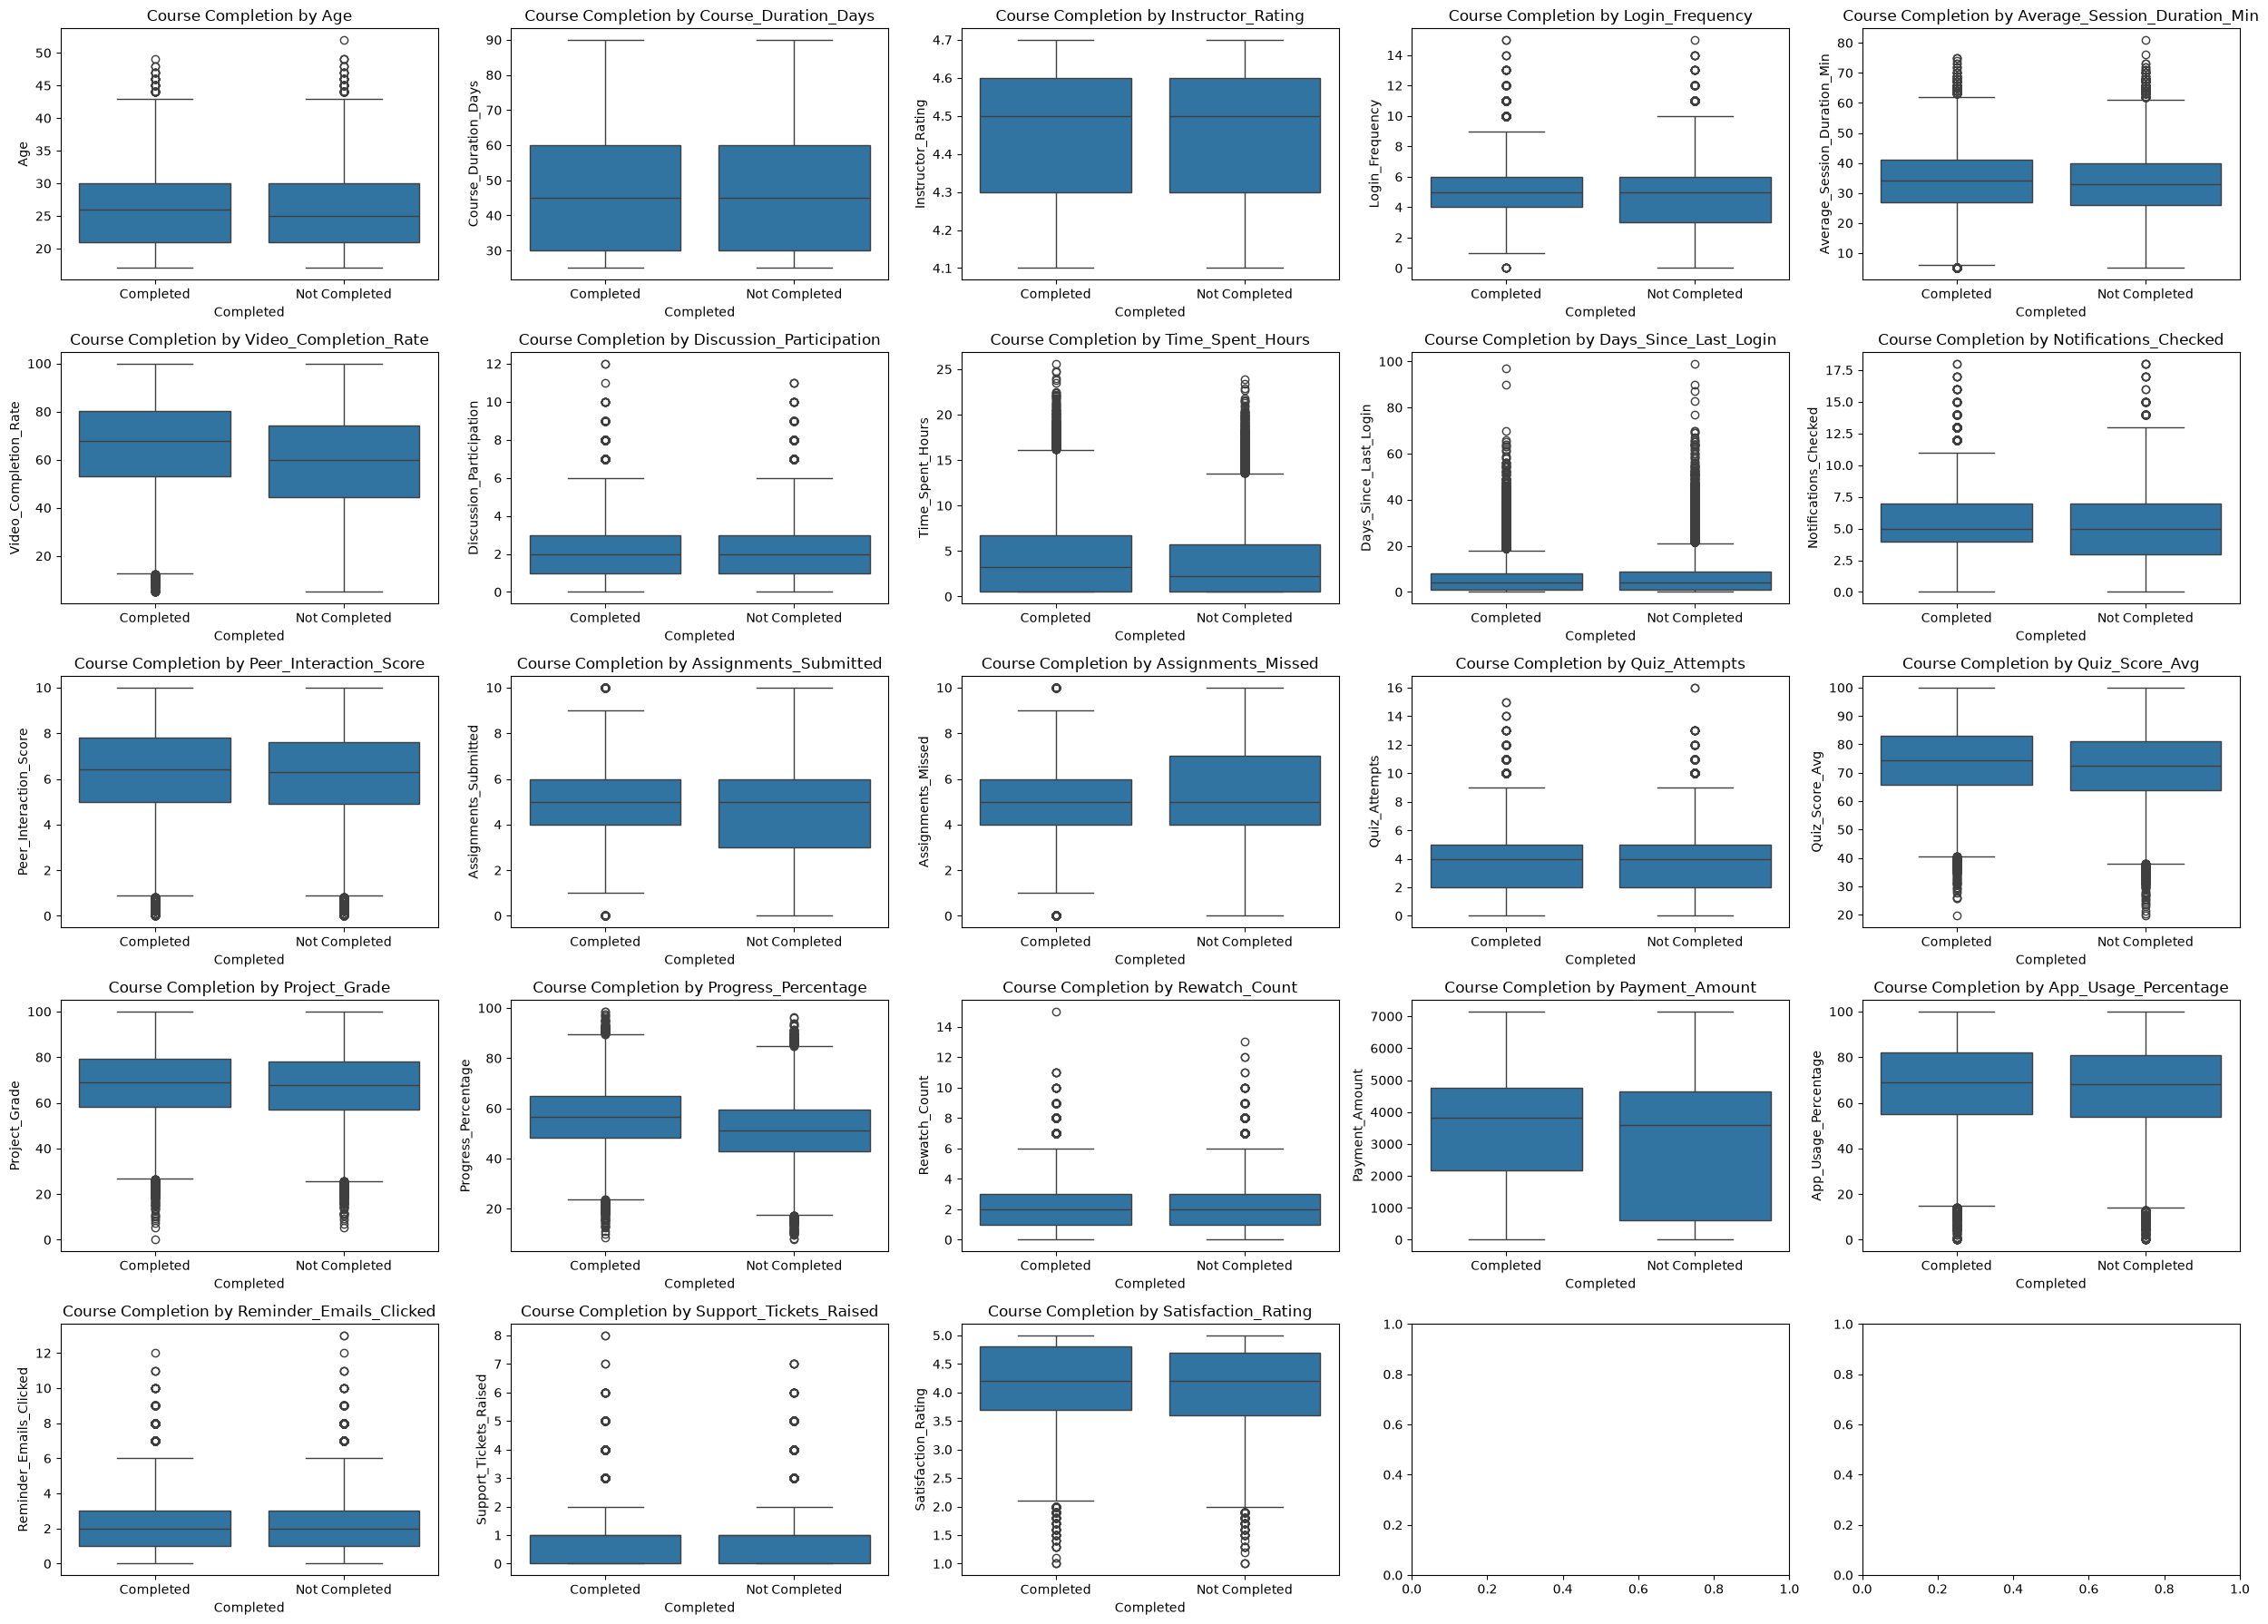

In [12]:
fig, axes = plt.subplots(5, 5, figsize=(25, 18))

for ax, col in zip(axes.flat, numerical_cols):
    sns.boxplot(
        data=courses,
        x='Completed',
        y=col, 
        ax=ax
    )
    
    ax.set_title(f"Course Completion by {col}")
    ax.set_xlabel("Completed")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

Most numerical features have outliers which will be investigated as columns to keep or not.

In [13]:
for col in numerical_cols:
    Q1 = courses[col].quantile(0.25)
    Q3 = courses[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = courses[
        (courses[col] < lower_bound) |
        (courses[col] > upper_bound)
    ]

    print(f"\n{col}")
    print(f"Lower bound: {lower_bound}")
    print(f"Upper bound: {upper_bound}")
    print(f"Number of outliers: {len(outliers)}")


Age
Lower bound: 7.5
Upper bound: 43.5
Number of outliers: 147

Course_Duration_Days
Lower bound: -15.0
Upper bound: 105.0
Number of outliers: 0

Instructor_Rating
Lower bound: 3.85
Upper bound: 5.049999999999999
Number of outliers: 0

Login_Frequency
Lower bound: -1.5
Upper bound: 10.5
Number of outliers: 374

Average_Session_Duration_Min
Lower bound: 6.0
Upper bound: 62.0
Number of outliers: 582

Video_Completion_Rate
Lower bound: 5.0
Upper bound: 121.0
Number of outliers: 0

Discussion_Participation
Lower bound: -2.0
Upper bound: 6.0
Number of outliers: 1366

Time_Spent_Hours
Lower bound: -8.05
Upper bound: 14.75
Number of outliers: 1102

Days_Since_Last_Login
Lower bound: -11.0
Upper bound: 21.0
Number of outliers: 4048

Notifications_Checked
Lower bound: -0.5
Upper bound: 11.5
Number of outliers: 1133

Peer_Interaction_Score
Lower bound: 0.7000000000000011
Upper bound: 11.899999999999999
Number of outliers: 323

Assignments_Submitted
Lower bound: 1.0
Upper bound: 9.0
Number of ou

In [14]:
# Check the range of numerical variables
courses[numerical_cols].agg(['min', 'max']).T

,min,max
Age,17.0,52.0
Course_Duration_Days,25.0,90.0
Instructor_Rating,4.1,4.7
Login_Frequency,0.0,15.0
Average_Session_Duration_Min,5.0,81.0
Video_Completion_Rate,5.0,99.9
Discussion_Participation,0.0,12.0
Time_Spent_Hours,0.5,25.6
Days_Since_Last_Login,0.0,99.0
Notifications_Checked,0.0,18.0


Outliers were identified using the Interquartile Range (IQR) method. Several numerical features, particularly those related to student engagement (e.g., Days Since Last Login, Support Tickets Raised, and Time Spent Hours), exhibited values outside the calculated IQR bounds.

To determine whether these represented data quality issues, the minimum and maximum values of each numerical feature were examined. All observed values fell within realistic and valid ranges. For example, students' ages ranged from 17 to 52 years, quiz scores ranged from 19.6 to 100, and progress percentages ranged from 7.6% to 98.6%.

Therefore, these observations are considered statistical outliers rather than erroneous values. They likely reflect genuine differences in learner behavior and engagement. Therefore, the outliers will be retained for subsequent analysis and model development to preserve valuable information that may improve predictive performance.

-
    - Categorical Features

In [15]:
categorical_cols = courses.select_dtypes(include=['str']).columns
print(categorical_cols)

Index(['Student_ID', 'Name', 'Gender', 'Education_Level', 'Employment_Status',
       'City', 'Device_Type', 'Internet_Connection_Quality', 'Course_ID',
       'Course_Name', 'Category', 'Course_Level', 'Enrollment_Date',
       'Payment_Mode', 'Fee_Paid', 'Discount_Used', 'Completed'],
      dtype='str')


In [16]:
courses[categorical_cols].nunique()

Student_ID                     100000
Name                              300
Gender                              3
Education_Level                     5
Employment_Status                   4
City                               15
Device_Type                         3
Internet_Connection_Quality         3
Course_ID                           8
Course_Name                         8
Category                            5
Course_Level                        3
Enrollment_Date                   721
Payment_Mode                        6
Fee_Paid                            2
Discount_Used                       2
Completed                           2
dtype: int64

In [17]:
 # Dropping the columns we don't really need for analysis
courses1 = courses.drop(columns=['Student_ID', 'Name', 'City', 'Course_ID', 'Enrollment_Date', 'Payment_Mode'])

In [18]:
courses1.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 34 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Gender                        100000 non-null  str    
 1   Age                           100000 non-null  int64  
 2   Education_Level               100000 non-null  str    
 3   Employment_Status             100000 non-null  str    
 4   Device_Type                   100000 non-null  str    
 5   Internet_Connection_Quality   100000 non-null  str    
 6   Course_Name                   100000 non-null  str    
 7   Category                      100000 non-null  str    
 8   Course_Level                  100000 non-null  str    
 9   Course_Duration_Days          100000 non-null  int64  
 10  Instructor_Rating             100000 non-null  float64
 11  Login_Frequency               100000 non-null  int64  
 12  Average_Session_Duration_Min  100000 non-null  int64  
 

In [19]:
# Remaining categorical features
categorical_cols = courses1.select_dtypes(include=['str']).columns
print(categorical_cols)

Index(['Gender', 'Education_Level', 'Employment_Status', 'Device_Type',
       'Internet_Connection_Quality', 'Course_Name', 'Category',
       'Course_Level', 'Fee_Paid', 'Discount_Used', 'Completed'],
      dtype='str')


### **Separating features(X) and target(y)**

Remember: 

- training data → teach the model
- testing data → evaluate how well it works on unseen students

In [20]:
X = courses1.drop('Completed', axis=1)
y = courses1['Completed']

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

#### **Encoding the data after splitting to prevent data leakage**

In [22]:
# Encoding categorical variables
courses1[categorical_cols].nunique()

Gender                         3
Education_Level                5
Employment_Status              4
Device_Type                    3
Internet_Connection_Quality    3
Course_Name                    8
Category                       5
Course_Level                   3
Fee_Paid                       2
Discount_Used                  2
Completed                      2
dtype: int64

**Encoding Binary Variables i.e: "Yes or No"**

    - Training Set

In [23]:
# Fee Paid
fees_paid = {
    'No': 0,
    'Yes': 1
}

X_train['Fee_Paid'] = X_train['Fee_Paid'].map(fees_paid)

In [24]:
# Discount Used
discount_use = {
    'No': 0,
    'Yes': 1
}

X_train['Discount_Used'] = X_train['Discount_Used'].map(discount_use)

    - Testing Set

In [25]:
# Fees Paid
X_test['Fee_Paid'] = X_test['Fee_Paid'].map(fees_paid)

In [26]:
# Discount Used
X_test['Discount_Used'] = X_test['Discount_Used'].map(discount_use)

In [27]:
# Fee_Paid
courses1['Fee_Paid'] = courses1['Fee_Paid'].map({
    'No': 0,
    'Yes': 1
})

In [28]:
# Discount_Used
courses1['Discount_Used'] = courses1['Discount_Used'].map({
    'No': 0,
    'Yes': 1
})

**Encoding Ordinal variables: Education_Level, Internet_Connection_Quality and Course_Level since these features follow a natural order.**

    - Training Set

In [29]:
education_levels = {
    'HighSchool': 0,
    'Diploma': 1,
    'Bachelor': 2,
    'Master': 3,
    'PhD': 4
}

X_train['Education_Level'] = X_train['Education_Level'].map(education_levels)

In [30]:
internet_connectivity = {
    'Low': 0,
    'Medium': 1,
    'High': 2
}

X_train['Internet_Connection_Quality'] = X_train['Internet_Connection_Quality'].map(internet_connectivity)

In [31]:
course_levels = {
    'Beginner': 0,
    'Intermediate': 1,
    'Advanced': 2
}

X_train['Course_Level'] = X_train['Course_Level'].map(course_levels)

    - Testing Set

In [32]:
# Education
X_test['Education_Level'] = X_test['Education_Level'].map(education_levels)

In [33]:
# Internet Connection
X_test['Internet_Connection_Quality'] = X_test['Internet_Connection_Quality'].map(internet_connectivity)

In [34]:
# Course level
X_test['Course_Level'] = X_test['Course_Level'].map(course_levels)

**One-hot encode the remaining categorical variables**

    - Training Set

In [35]:
X_train = pd.get_dummies(
    X_train,
    columns=[
        'Gender',
        'Employment_Status',
        'Device_Type',
        'Course_Name',
        'Category'
    ],
    dtype=int
)


    - Testing Set

In [36]:
X_test = pd.get_dummies(
    X_test,
    columns=[
        'Gender',
        'Employment_Status',
        'Device_Type',
        'Course_Name',
        'Category'
    ],
    dtype=int
)

In [37]:
# Aligning the columns
X_train, X_test = X_train.align(
    X_test,
    join='left',
    axis=1,
    fill_value=0
)

In [38]:
# Confirming that encoding worked
X_train.head()

,Age,Education_Level,Internet_Connection_Quality,Course_Level,Course_Duration_Days,Instructor_Rating,Login_Frequency,Average_Session_Duration_Min,Video_Completion_Rate,Discussion_Participation,...,Course_Name_Introduction to AI,Course_Name_Machine Learning A-Z,Course_Name_Python Basics,Course_Name_Statistics for Data Science,Course_Name_UI/UX Design Fundamentals,Category_Business,Category_Design,Category_Marketing,Category_Math,Category_Programming
31074,35,2,0,0,45,4.6,5,20,37.9,2,...,0,0,1,0,0,0,0,0,0,1
95822,28,2,2,0,25,4.1,7,25,86.5,0,...,0,0,0,0,0,1,0,0,0,0
36175,23,0,1,0,45,4.6,9,43,26.1,3,...,0,0,1,0,0,0,0,0,0,1
42479,28,2,1,0,30,4.3,7,32,44.3,1,...,0,0,0,0,0,0,0,1,0,0
38953,17,2,1,0,30,4.3,4,50,58.9,0,...,0,0,0,0,0,0,0,1,0,0


In [39]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 80000 entries, 31074 to 54493
Data columns (total 51 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Age                                       80000 non-null  int64  
 1   Education_Level                           80000 non-null  int64  
 2   Internet_Connection_Quality               80000 non-null  int64  
 3   Course_Level                              80000 non-null  int64  
 4   Course_Duration_Days                      80000 non-null  int64  
 5   Instructor_Rating                         80000 non-null  float64
 6   Login_Frequency                           80000 non-null  int64  
 7   Average_Session_Duration_Min              80000 non-null  int64  
 8   Video_Completion_Rate                     80000 non-null  float64
 9   Discussion_Participation                  80000 non-null  int64  
 10  Time_Spent_Hours                          8000

In [40]:
# Encoding the Target Variable
# Training set
y_train = y_train.map({
    'Not Completed': 0,
    'Completed': 1
})

In [41]:
# Testing Set
y_test = y_test.map({
    'Not Completed': 0,
    'Completed': 1
})

In [42]:
print(y_train.unique())

[0 1]


In [43]:
# Checking the data types have no text columns remaining
X_train.info()

<class 'pandas.DataFrame'>
Index: 80000 entries, 31074 to 54493
Data columns (total 51 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Age                                       80000 non-null  int64  
 1   Education_Level                           80000 non-null  int64  
 2   Internet_Connection_Quality               80000 non-null  int64  
 3   Course_Level                              80000 non-null  int64  
 4   Course_Duration_Days                      80000 non-null  int64  
 5   Instructor_Rating                         80000 non-null  float64
 6   Login_Frequency                           80000 non-null  int64  
 7   Average_Session_Duration_Min              80000 non-null  int64  
 8   Video_Completion_Rate                     80000 non-null  float64
 9   Discussion_Participation                  80000 non-null  int64  
 10  Time_Spent_Hours                          8000

In [44]:
X_test.info()

<class 'pandas.DataFrame'>
Index: 20000 entries, 12639 to 28380
Data columns (total 51 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Age                                       20000 non-null  int64  
 1   Education_Level                           20000 non-null  int64  
 2   Internet_Connection_Quality               20000 non-null  int64  
 3   Course_Level                              20000 non-null  int64  
 4   Course_Duration_Days                      20000 non-null  int64  
 5   Instructor_Rating                         20000 non-null  float64
 6   Login_Frequency                           20000 non-null  int64  
 7   Average_Session_Duration_Min              20000 non-null  int64  
 8   Video_Completion_Rate                     20000 non-null  float64
 9   Discussion_Participation                  20000 non-null  int64  
 10  Time_Spent_Hours                          2000

In [45]:
X_train.shape, X_test.shape

((80000, 51), (20000, 51))

Calculating Variance Inflation Factor(VIF).

Variance Inflation Factor (VIF) analysis is conducted to identify multicollinearity among the predictor variables. Multicollinearity occurs when independent variables contain similar information, which can make model coefficients unstable and reduce interpretability.

In [46]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [47]:
vif = pd.DataFrame()

vif['Feature'] = X_train.columns

vif['VIF'] = [
    variance_inflation_factor(X_train.values, i)
    for i in range(X_train.shape[1])
]

vif['VIF'] = vif['VIF'].round(2)

vif.sort_values(by='VIF', ascending=False)

C:\Users\Admin\AppData\Local\Temp\ipykernel_15320\1610397589.py:6: UserWarning: The design matrix is poorly conditioned (condition number=2.54e+16). VIF calculations may be numerically unstable.
  variance_inflation_factor(X_train.values, i)
c:\Users\Admin\Desktop\Machine Learning Foundations\.env\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\Admin\Desktop\Machine Learning Foundations\.env\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\Admin\Desktop\Machine Learning Foundations\.env\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquel

,Feature,VIF
35,Device_Type_Laptop,71682888.08
42,Course_Name_Machine Learning A-Z,44936030.01
48,Category_Marketing,44627229.59
44,Course_Name_Statistics for Data Science,41391203.42
37,Device_Type_Tablet,34781593.36
49,Category_Math,33103635.94
47,Category_Design,22623389.54
45,Course_Name_UI/UX Design Fundamentals,16327104.70
43,Course_Name_Python Basics,14443453.07
36,Device_Type_Mobile,13207331.12


### Course-related features

The VIF results showed extremely high values for several course-related features, including `Course_Name`, `Category`, and `Course_Level`. This indicates that these variables contain overlapping information. For example, a specific course name can often predict its category and difficulty level, meaning the model receives similar information from multiple features. These variables will be reviewed to determine which ones are most useful for the early warning system.

### Instructor Rating

`Instructor_Rating` showed a very high VIF value, suggesting that it may be strongly related to course-specific information. This may occur if each course has a consistent instructor rating, making it similar to the course identifier. Further evaluation will be done to determine whether it provides additional predictive value.

### Course Duration, Progress, and Engagement Features

Features such as `Course_Duration_Days`, `Progress_Percentage`, `Video_Completion_Rate`, and `Assignments_Submitted` showed high VIF values. This suggests that these variables may be measuring similar aspects of learner engagement. For example, students who complete more videos are also likely to have higher progress percentages and submit more assignments.

However, these features are important for an early warning system because they directly represent student learning behaviour. Their removal will therefore depend on model performance and their practical importance.

### Payment-related features

`Payment_Amount` and `Fee_Paid` showed relatively high VIF values, indicating some overlap between these variables. Since payment amount can often indicate whether a fee was paid, both variables may not be necessary. One of them may be removed to reduce redundancy.

### Features with Low VIF Values

Most demographic and behavioural features, including `Age`, `Education_Level`, `App_Usage_Percentage`, `Login_Frequency`, `Satisfaction_Rating`, and `Internet_Connection_Quality`, had VIF values close to 1. This indicates that these features provide unique information and have little correlation with other predictors.

### Overall Conclusion

The VIF analysis identified areas of feature overlap, particularly among course-related and engagement variables. Features will not be removed based only on VIF values; instead, decisions will consider both statistical results and their importance in building a practical early warning system for identifying students at risk of not completing courses.



In [48]:
print(X.shape)
print(y.shape)

(100000, 33)
(100000,)


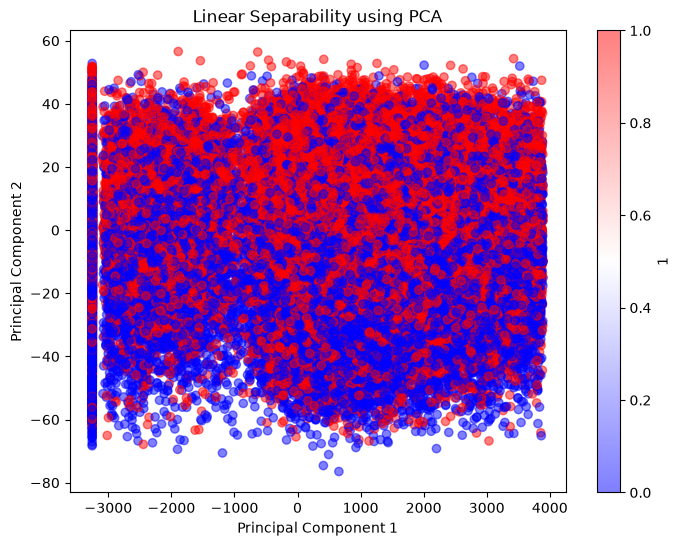

In [49]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce to 2 dimensions
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)

plt.figure(figsize=(8,6))
plt.scatter(
    X_train_pca[:,0],
    X_train_pca[:,1],
    c=y_train,
    cmap='bwr',
    alpha=0.5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Linear Separability using PCA")
plt.colorbar(label=1)
plt.show()

The PCA plot shows a large overlap between the Completed and Not Completed classes. This indicates that the data is not linearly separable, meaning a linear model may not classify the students perfectly. Therefore, it is useful to compare both linear and non-linear models to determine which performs better.

In [50]:
y_train.value_counts(normalize=True)*100

Completed
0    50.97
1    49.03
Name: proportion, dtype: float64

This means that stratify worked in that the training data has the same distribution as the original dataset. So the model will not be biased toward predicting only one class.

In [105]:
X_train.columns.tolist()

['Age',
 'Education_Level',
 'Internet_Connection_Quality',
 'Course_Level',
 'Course_Duration_Days',
 'Instructor_Rating',
 'Login_Frequency',
 'Average_Session_Duration_Min',
 'Video_Completion_Rate',
 'Discussion_Participation',
 'Time_Spent_Hours',
 'Days_Since_Last_Login',
 'Notifications_Checked',
 'Peer_Interaction_Score',
 'Assignments_Submitted',
 'Assignments_Missed',
 'Quiz_Attempts',
 'Quiz_Score_Avg',
 'Project_Grade',
 'Progress_Percentage',
 'Rewatch_Count',
 'Fee_Paid',
 'Discount_Used',
 'Payment_Amount',
 'App_Usage_Percentage',
 'Reminder_Emails_Clicked',
 'Support_Tickets_Raised',
 'Satisfaction_Rating',
 'Gender_Female',
 'Gender_Male',
 'Gender_Other',
 'Employment_Status_Employed',
 'Employment_Status_Self-Employed',
 'Employment_Status_Student',
 'Employment_Status_Unemployed',
 'Device_Type_Laptop',
 'Device_Type_Mobile',
 'Device_Type_Tablet',
 'Course_Name_Data Analysis with Python',
 'Course_Name_Digital Marketing Essentials',
 'Course_Name_Excel for Busines

#### **Feature Scaling - as the features are measured on very different scales.**

We use the standard scaler because the dataset contains numerical features measured on different scales, and some machine learning models are sensitive to those differences.

In [51]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

X_train_scaled.shape

(80000, 51)

We want to the scaler to learn the training data statistics only. The test set should remain unseen.

### Comparing Models

#### **1. Logistic Regression**

In [52]:
from sklearn.linear_model import LogisticRegression

In [53]:
# Creating the model
log_model = LogisticRegression(random_state=42)

In [54]:
# Training the model
log_model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solve

In [55]:
# Making Predictions
y_pred_log = log_model.predict(X_test_scaled)

In [56]:
# Evaluating the model
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy = accuracy_score(y_test, y_pred_log)*100

print("Accuracy:", accuracy)
print("\nClassification Report:\n", classification_report(y_test, y_pred_log))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_log))

Accuracy: 59.940000000000005

Classification Report:
               precision    recall  f1-score   support

           0       0.60      0.62      0.61     10194
           1       0.59      0.58      0.59      9806

    accuracy                           0.60     20000
   macro avg       0.60      0.60      0.60     20000
weighted avg       0.60      0.60      0.60     20000


Confusion Matrix:
 [[6318 3876]
 [4136 5670]]


The model achieved an accuracy of 59.9%, indicating that it correctly predicted approximately 60% of student outcomes.

The classification report showed balanced performance between the two classes. For students who did not complete the course, the model achieved a recall of 58%, meaning that it successfully identified 62% of students who were at risk of non-completion. However, 42% of students who did not complete were incorrectly classified as completing.

The confusion matrix showed that the model correctly identified 6,314 students who did not complete and 5,669 students who completed. It also classified 3880 students as those who did not complete but actually completed(False Positives), and 4137 students as those who completed but eventually did not complete(False Negatives).

#### **2. Random Forest**

In [57]:
from sklearn.ensemble import RandomForestClassifier

In [58]:
# Creating the model
rf_model = RandomForestClassifier(random_state=42)

In [59]:
# Training the model
rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [60]:
# Making Predictions
y_pred_rf = rf_model.predict(X_test)

In [61]:
# Evaluate Model
accuracy = accuracy_score(y_test, y_pred_rf)*100

print("Accuracy:", accuracy)
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

Accuracy: 58.595

Classification Report:
               precision    recall  f1-score   support

           0       0.59      0.62      0.60     10194
           1       0.58      0.55      0.57      9806

    accuracy                           0.59     20000
   macro avg       0.59      0.59      0.59     20000
weighted avg       0.59      0.59      0.59     20000


Confusion Matrix:
 [[6279 3915]
 [4366 5440]]


Random Forest achieved an accuracy of 58.5%, lower than that for Logistic Regression.

The confusion matrix showed that the model correctly identified **6,338** students who did not complete and **5,370** students who completed. It also classified **3,856** students as those who did not complete but actually completed(False Positives), and **4,436** students as those who completed but eventually did not complete(False Negatives).

#### **3. Decision Tree**

In [62]:
from sklearn.tree import DecisionTreeClassifier


In [63]:
# Creating the model
dt_model = DecisionTreeClassifier(random_state=42)

In [64]:
# Training the model
dt_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [65]:
# Making Predictions
y_pred_dt = dt_model.predict(X_test)

In [66]:
# Evaluating the model
accuracy = accuracy_score(y_test, y_pred_dt)*100

print("Accuracy:", accuracy)
print("\nClassification Report:\n", classification_report(y_test, y_pred_dt))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))

Accuracy: 53.125

Classification Report:
               precision    recall  f1-score   support

           0       0.54      0.54      0.54     10194
           1       0.52      0.52      0.52      9806

    accuracy                           0.53     20000
   macro avg       0.53      0.53      0.53     20000
weighted avg       0.53      0.53      0.53     20000


Confusion Matrix:
 [[5482 4712]
 [4663 5143]]


The Decision Tree model achieved an accuracy of 53.4%

The confusion matrix showed that the model correctly identified **5,473** students who did not complete and **5,194** students who completed. It also classified **4,721** students as those who did not complete but actually completed(False Positives), and **4,612** students as those who completed but eventually did not complete(False Negatives).

#### **4. XGBoost**

In [67]:
from xgboost import XGBClassifier

In [68]:
# Creating the model
xgb_model = XGBClassifier(random_state=42, eval_metric="logloss")

In [69]:
# Training the model
xgb_model.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [70]:
# Making predictions
y_pred_xgb = xgb_model.predict(X_test)

In [71]:
# Evaluating the model
accuracy = accuracy_score(y_test, y_pred_xgb)*100

print("Accuracy:", accuracy)
print("\nClassification Report:\n", classification_report(y_test, y_pred_xgb))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))

Accuracy: 58.51499999999999

Classification Report:
               precision    recall  f1-score   support

           0       0.59      0.61      0.60     10194
           1       0.58      0.56      0.57      9806

    accuracy                           0.59     20000
   macro avg       0.58      0.58      0.58     20000
weighted avg       0.58      0.59      0.58     20000


Confusion Matrix:
 [[6175 4019]
 [4278 5528]]


The XGBoost model achieved an accuracy of approximately 59%

The confusion matrix showed that the model correctly identified 6,104 students who did not complete and 5,615 students who completed. It also classified 4,090 students as those who did not complete but actually completed(False Positives), and 4191 students as those who completed but eventually did not complete(False Negatives).

#### **6. K-Nearest Neighbours**

In [72]:
from sklearn.neighbors import KNeighborsClassifier

In [73]:
# Creating the model
knn_model = KNeighborsClassifier(n_neighbors=5)

In [74]:
# Training the model
knn_model.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [75]:
# Making predictions
y_pred_knn = knn_model.predict(X_test_scaled)

In [76]:
# Evaluate the model
print("Accuracy:\n", accuracy_score(y_test, y_pred_knn))
print("\nClassification Report:\n", classification_report(y_test, y_pred_knn))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_knn))

Accuracy:
 0.53135

Classification Report:
               precision    recall  f1-score   support

           0       0.54      0.55      0.54     10194
           1       0.52      0.52      0.52      9806

    accuracy                           0.53     20000
   macro avg       0.53      0.53      0.53     20000
weighted avg       0.53      0.53      0.53     20000


Confusion Matrix:
 [[5575 4619]
 [4754 5052]]


In [77]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report)

#### **Comparing the models**

In [78]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Decision Tree",
        "XGBoost",
        "KNN"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_xgb),
        accuracy_score(y_test, y_pred_knn)
    ],
    "Precision": [
        precision_score(y_test, y_pred_log),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_xgb),
        precision_score(y_test, y_pred_knn)
    ],
    "Recall": [
        recall_score(y_test, y_pred_log),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_xgb),
        recall_score(y_test, y_pred_knn)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_log),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_xgb),
        f1_score(y_test, y_pred_knn)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.59940,0.593966,0.578217,0.585986
1,Random Forest,0.58595,0.581507,0.554762,0.567820
2,Decision Tree,0.53125,0.521867,0.524475,0.523168
3,XGBoost,0.58515,0.579030,0.563736,0.571281
4,KNN,0.53135,0.522387,0.515195,0.518766


#### **Error Analysis**

In [108]:
from sklearn.metrics import ConfusionMatrixDisplay

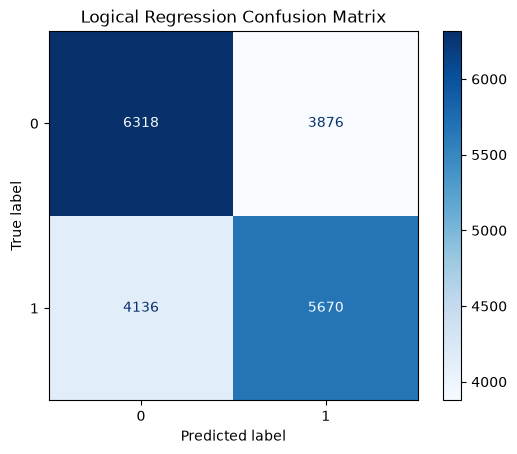

In [109]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_log,
    cmap="Blues"
)

plt.title("Logical Regression Confusion Matrix")
plt.show()

In [79]:
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score

# Function for model error analysis
def error_analysis(y_true, y_pred, model_name):
    
    cm = confusion_matrix(y_true, y_pred)
    
    tn, fp, fn, tp = cm.ravel()
    
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "False Positives": fp,
        "False Negatives": fn,
        "Recall (Not Completed)": recall_score(y_true, y_pred, pos_label=0),
        "Recall (Completed)": recall_score(y_true, y_pred, pos_label=1)
    }


# Compare all models
results = []

results.append(error_analysis(y_test, y_pred_log, "Logistic Regression"))
results.append(error_analysis(y_test, y_pred_rf, "Random Forest"))
results.append(error_analysis(y_test, y_pred_xgb, "XGBoost"))
results.append(error_analysis(y_test, y_pred_knn, "KNN"))


# Create comparison dataframe
error_comparison = pd.DataFrame(results)

# Sort by recall of students who did not complete
error_comparison.sort_values(
    by="Recall (Not Completed)",
    ascending=False
)

,Model,Accuracy,False Positives,False Negatives,Recall (Not Completed),Recall (Completed)
0,Logistic Regression,0.59940,3876,4136,0.619776,0.578217
1,Random Forest,0.58595,3915,4366,0.615951,0.554762
2,XGBoost,0.58515,4019,4278,0.605748,0.563736
3,KNN,0.53135,4619,4754,0.546890,0.515195


The error analysis showed that Logistic Regression provided the best overall balance among the evaluated models. It achieved the highest accuracy (59.94%), the lowest number of false negatives (4,136), and the highest recall for identifying students who did not complete the course (61.98%).

Since the main goal of this project is to develop an early warning system, reducing false negatives is important because these represent students who are at risk of non-completion but are not identified by the model. Logistic Regression was therefore selected as the final model due to its ability to identify at-risk students while also providing better interpretability compared to the other models.

#### **Feature Importance**

We do feature importance to try and asnwer "Which Student characteristics contribute most to predicting course completion"

For Logistic regression, remember:
- Positive coefficient - increases likelihood of Completed (1)
- Negative coefficient - increases likelihood of Not Completed (0)
- Larger absolute coefficient - stronger influence

In [80]:
# Logistic Regression
# Get coefficients
log_coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": log_model.coef_[0]
})

# Add absolute coefficient for ranking
log_coefficients["Absolute_Coefficient"] = abs(
    log_coefficients["Coefficient"]
)

# Sort by strongest influence
lr_coefficients = log_coefficients.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

lr_coefficients.head(15)

,Feature,Coefficient,Absolute_Coefficient
8,Video_Completion_Rate,0.238999,0.238999
19,Progress_Percentage,0.204448,0.204448
10,Time_Spent_Hours,0.180066,0.180066
17,Quiz_Score_Avg,0.116799,0.116799
21,Fee_Paid,0.115134,0.115134
14,Assignments_Submitted,0.092744,0.092744
23,Payment_Amount,0.086068,0.086068
11,Days_Since_Last_Login,-0.066117,0.066117
24,App_Usage_Percentage,0.026255,0.026255
15,Assignments_Missed,-0.020508,0.020508


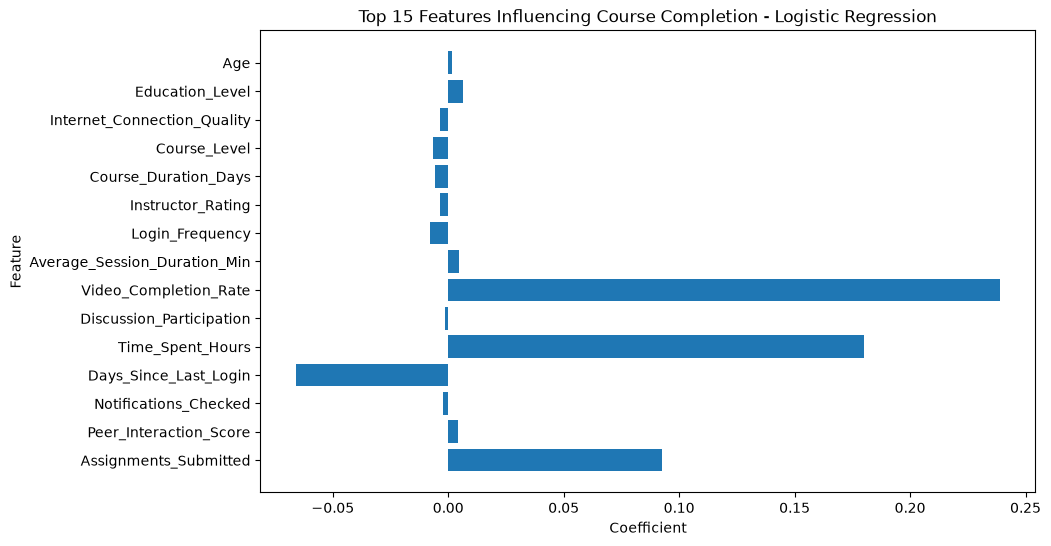

In [81]:
# Visualizing the strongest predictors
top_features = log_coefficients.head(15)

plt.figure(figsize=(10,6))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.gca().invert_yaxis()

plt.title("Top 15 Features Influencing Course Completion - Logistic Regression")
plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.show()

The strongest predictors of course completion were:

- *Video Completion Rate*
- *Progress Percentage*
- *Time Spent Hours*
- *Quiz Score Average*
- *Fee Paid*

- *Days Since Last Login* had a **negative effect**, meaning longer inactivity increased the risk of non-completion.

Students who actively engage with course content and assessments are more likely to complete, while inactivity increases dropout risk.

In [82]:
# Random Forest
# Get feature importance
rf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort highest to lowest
rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

rf_importance.head(15)

,Feature,Importance
19,Progress_Percentage,0.072139
8,Video_Completion_Rate,0.067418
17,Quiz_Score_Avg,0.056607
18,Project_Grade,0.053772
23,Payment_Amount,0.049020
13,Peer_Interaction_Score,0.048982
24,App_Usage_Percentage,0.048064
7,Average_Session_Duration_Min,0.045936
10,Time_Spent_Hours,0.044160
0,Age,0.039789


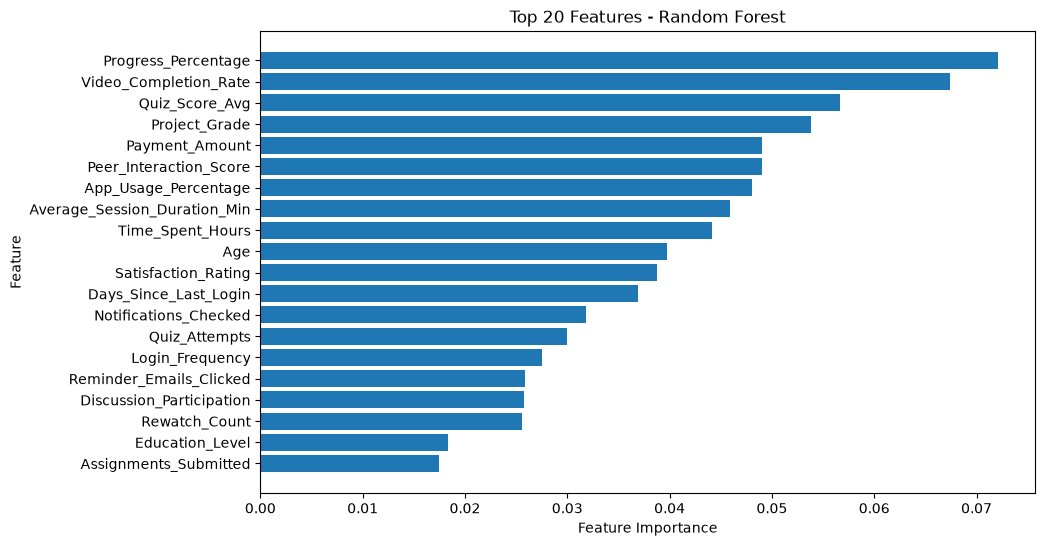

In [83]:
# Visualizing it
top_rf = rf_importance.head(20)

plt.figure(figsize=(10,6))

plt.barh(
    top_rf["Feature"],
    top_rf["Importance"]
)

plt.gca().invert_yaxis()

plt.title("Top 20 Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.show()

The most important features were:
- *Progress Percentage*
- *Video Completion Rate*
- *Quiz Score Average*
- *Project Grade*
- *Payment Amount*
- *Peer Interaction Score*
- *Time Spent Hours*

The model identified learning engagement, academic performance, and interaction with the platform as key factors influencing completion.

In [84]:
# XGBoost Feature Importance
xgb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
)

xgb_importance.head(15)

,Feature,Importance
21,Fee_Paid,0.141128
19,Progress_Percentage,0.090139
10,Time_Spent_Hours,0.030120
23,Payment_Amount,0.026069
8,Video_Completion_Rate,0.025523
17,Quiz_Score_Avg,0.022700
45,Course_Name_UI/UX Design Fundamentals,0.021596
34,Employment_Status_Unemployed,0.021584
41,Course_Name_Introduction to AI,0.021261
31,Employment_Status_Employed,0.020970


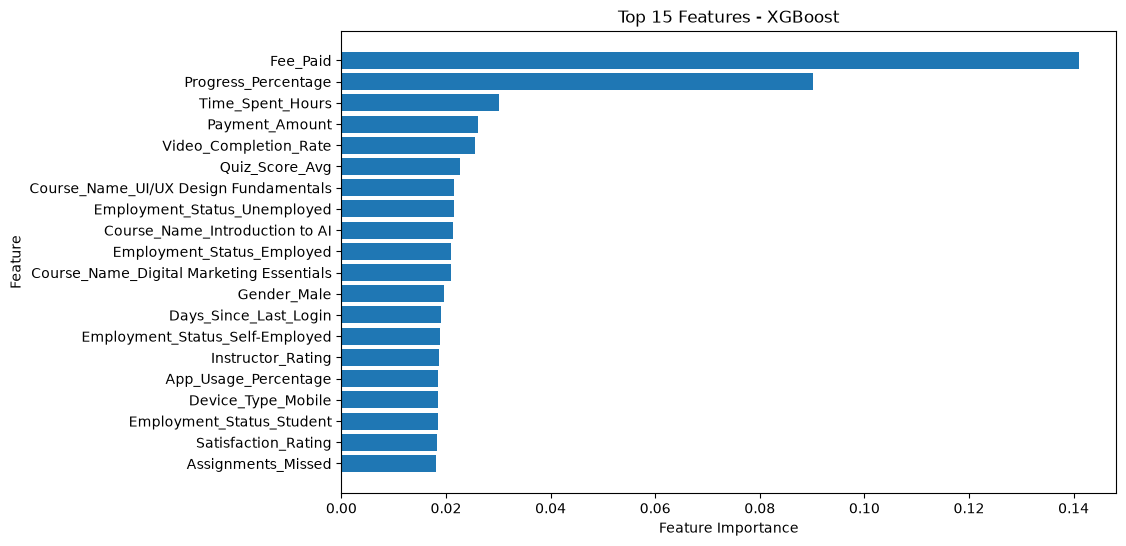

In [85]:
# Plotting it
top_xgb = xgb_importance.head(20)

plt.figure(figsize=(10,6))

plt.barh(
    top_xgb["Feature"],
    top_xgb["Importance"]
)

plt.gca().invert_yaxis()

plt.title("Top 15 Features - XGBoost")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.show()

The most important features were:
- *Fee Paid*
- *Progress Percentage*
- *Time Spent Hours*
- *Payment Amount*
- *Video Completion Rate*
- *Quiz Score Average*

XGBoost highlighted course progress, engagement behaviour, and financial commitment as major predictors of completion.

The models consistently identified these as the strongest predictors:

- *Progress Percentage*
- *Video Completion Rate*
- *Time Spent Hours*
- *Quiz Performance*
- *Financial Commitment (Fee Paid/Payment Amount)*
- *Recent Activity (Days Since Last Login)*

Overall conclusion:
Student engagement and learning progress are the main indicators of course completion. Students with low progress, low activity, and reduced interaction with course materials may be candidates for early intervention in an early warning system.

#### **Model Explainability**

We use SHAP for model explainability because it fits the model goal: 

"Why did the model classify this student as likely to complete or not complete?"

We also want to see:
- Which features push predictions toward Completed
- Which features push predictions toward Not Completed
- How much each feature contributes

In [86]:
import shap

c:\Users\Admin\Desktop\Machine Learning Foundations\.env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [87]:
# Creating the SHAP explainer
explainer = shap.LinearExplainer(
    log_model,
    X_train_scaled
)

Background dataset has 80000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=80000 when initializing the masker.


Creating a representative reference dataset of 100 students

In [88]:
# Creating a background sample of 100 students
background = shap.sample(
    X_train_scaled,
    100,
    random_state=42
)

In [89]:
# Creating a SHAP explainer for the background sample
explainer = shap.LinearExplainer(
    log_model,
    background
)

In [90]:
# Calculating SHAP values
shap_values = explainer.shap_values(
    X_test_scaled
)

In [91]:
# Checking the background sample shape
shap_values.shape

(20000, 51)

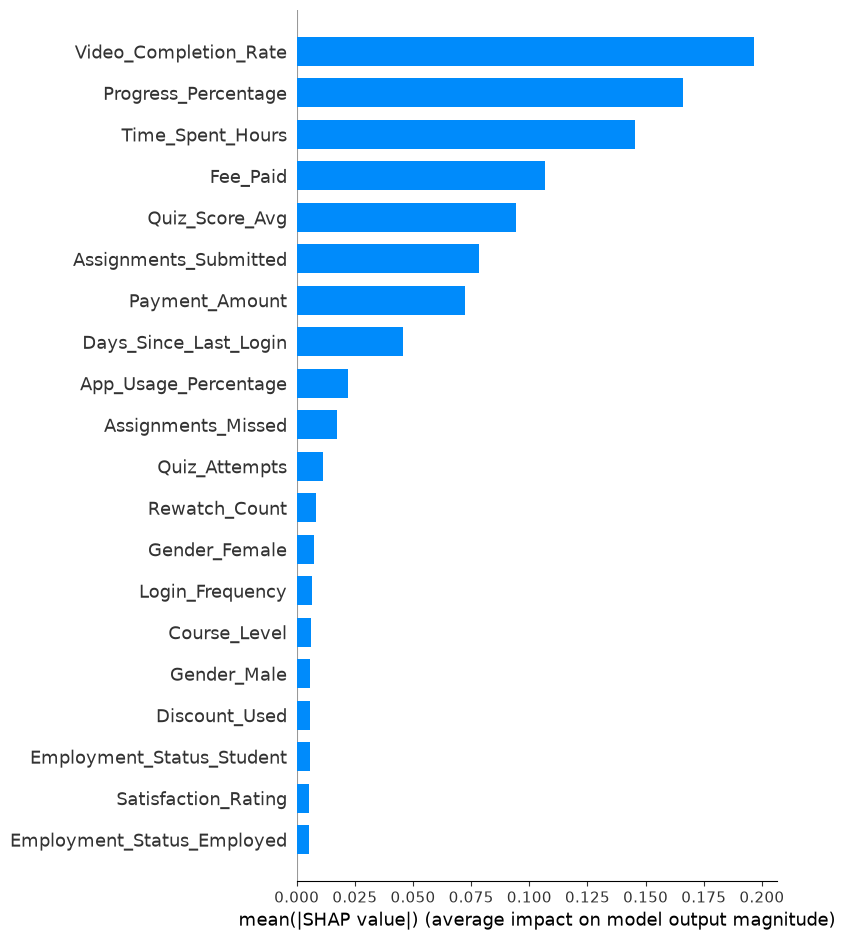

In [92]:
shap.summary_plot(
    shap_values,
    X_test_scaled,
    feature_names=X_test.columns,
    plot_type="bar"
)

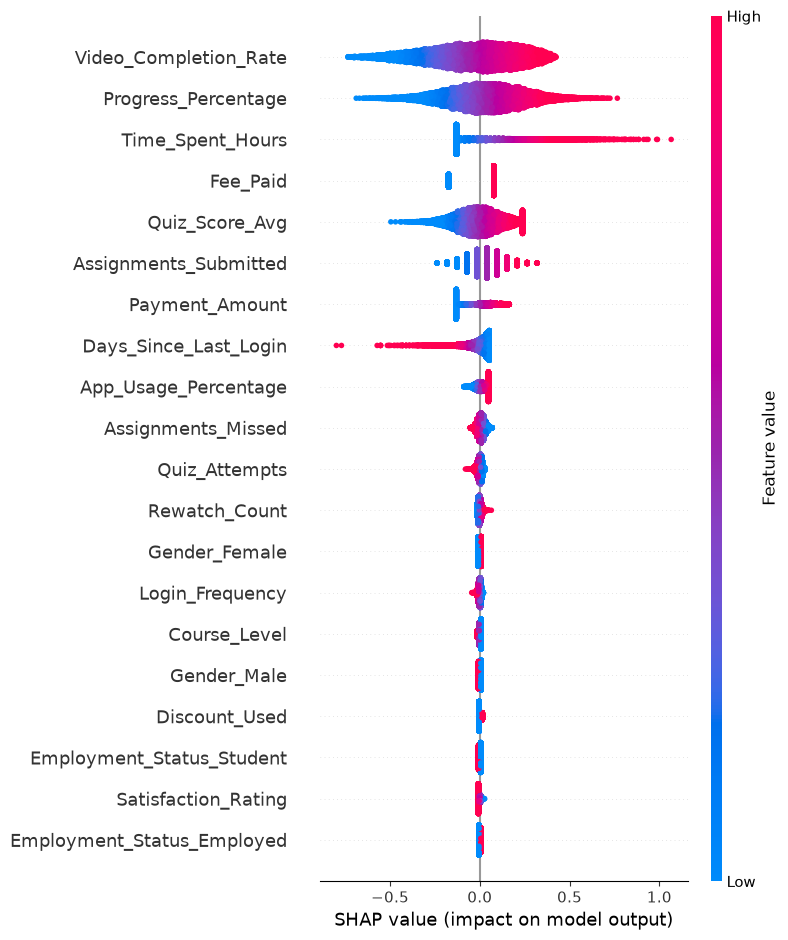

In [93]:
shap.summary_plot(
    shap_values,
    X_test_scaled,
    feature_names=X_test.columns
)

SHAP analysis confirmed that student engagement variables were the strongest contributors to course completion predictions. Video completion rate, progress percentage, and time spent learning had the greatest influence on model predictions. Other important factors included quiz performance, assignment submission, fee payment status, and recent login activity. Demographic characteristics showed relatively low influence, suggesting that learning behaviour provides stronger signals for identifying students at risk of non-completion.

#### **Hyperparameter Tuning**

In [ ]:
# Logistic Regression
from sklearn.model_selection import GridSearchCV

log = LogisticRegression(max_iter=1000)

param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "penalty": ["l1", "l2"],
    "solver": ["liblinear"]
}

grid_log = GridSearchCV(
    log,
    param_grid,
    cv=5,
    scoring="recall",
    n_jobs=-1
)

grid_log.fit(X_train_scaled, y_train)

print(grid_log.best_params_)

c:\Users\Admin\Desktop\Machine Learning Foundations\.env\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Admin\Desktop\Machine Learning Foundations\.env\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


{'C': 0.01, 'penalty': 'l1', 'solver': 'liblinear'}


In [95]:
best_log = grid_log.best_estimator_

y_pred_tuned_log = best_log.predict(X_test_scaled)

print(classification_report(y_test, y_pred_tuned_log))
print(confusion_matrix(y_test, y_pred_tuned_log))

              precision    recall  f1-score   support

           0       0.60      0.62      0.61     10194
           1       0.59      0.58      0.59      9806

    accuracy                           0.60     20000
   macro avg       0.60      0.60      0.60     20000
weighted avg       0.60      0.60      0.60     20000

[[6288 3906]
 [4110 5696]]


Hyperparameter tuning was performed on the selected Logistic Regression model using GridSearchCV to optimize model parameters. The tuned model showed performance similar to the baseline model, indicating that the default configuration was already well suited to the dataset. Therefore, the tuned Logistic Regression model was retained as the final model for the early warning system

In [106]:
# ==========================================
# SAVE FINAL MODEL AND PREPROCESSING OBJECTS
# ==========================================

import joblib

# Save the final trained Logistic Regression model
joblib.dump(
    best_log,
    "course_completion_model.pkl"
)

# Save the scaler used before model prediction
joblib.dump(
    scaler,
    "scaler.pkl"
)

# Save the final feature columns after encoding
# This ensures new Streamlit data matches training data
joblib.dump(
    X_train.columns.tolist(),
    "training_columns.pkl"
)


# ==========================================
# SAVE ENCODING MAPPINGS
# ==========================================

# Binary encoding mappings

fees_paid = {
    "No": 0,
    "Yes": 1
}

discount_used = {
    "No": 0,
    "Yes": 1
}


joblib.dump(
    fees_paid,
    "fees_paid_mapping.pkl"
)

joblib.dump(
    discount_used,
    "discount_used_mapping.pkl"
)


# Ordinal encoding mappings

education_levels = {
    "HighSchool": 0,
    "Diploma": 1,
    "Bachelor": 2,
    "Master": 3,
    "PhD": 4
}


internet_quality = {
    "Low": 0,
    "Medium": 1,
    "High": 2
}


course_levels = {
    "Beginner": 0,
    "Intermediate": 1,
    "Advanced": 2
}


joblib.dump(
    education_levels,
    "education_mapping.pkl"
)

joblib.dump(
    internet_quality,
    "internet_mapping.pkl"
)

joblib.dump(
    course_levels,
    "course_level_mapping.pkl"
)


print("All model files saved successfully!")

All model files saved successfully!


## Final Model Selection and Recommendations

After evaluating multiple classification models, including Logistic Regression, Random Forest, XGBoost, and K-Nearest Neighbors (KNN), Logistic Regression was selected as the final model.

The model comparison considered not only accuracy but also the ability to identify students at risk of non-completion. Since this project focuses on developing an early warning system, reducing false negatives was a key priority.

Logistic Regression achieved the best overall balance:

* Accuracy: **59.94%**
* False Negatives: **4,136**
* Recall for Not Completed students: **61.98%**

Although more complex models such as Random Forest and XGBoost were tested, they did not outperform Logistic Regression on this dataset. Additionally, Logistic Regression provided better interpretability, allowing the factors influencing predictions to be clearly understood.

---

## Feature Importance and Model Explainability

To understand the factors influencing course completion predictions, feature importance analysis and SHAP explainability were performed on the final model.

The analysis showed that student engagement-related features were the strongest predictors of course completion.

The most influential features included:

* **Video Completion Rate** – Students who completed more learning materials were more likely to complete the course.
* **Progress Percentage** – Higher progress through the course was associated with a greater likelihood of completion.
* **Time Spent Hours** – Increased learning activity was linked to successful completion.
* **Quiz Score Average** – Better assessment performance contributed positively to completion predictions.
* **Assignments Submitted** – Consistent coursework submission indicated stronger engagement.
* **Days Since Last Login** – Longer periods of inactivity were associated with increased risk of non-completion.
* **Fee Paid and Payment Amount** – Financial commitment showed a relationship with completion behaviour.

The explainability analysis also showed that demographic characteristics had lower predictive influence compared to behavioural and engagement features.

These findings suggest that monitoring learning behaviour provides stronger signals for identifying students who may require support.

---

## Recommendations

Based on the model findings, the following interventions can support early identification and assistance of at-risk students:

### 1. Monitor Student Engagement

Learning platforms can track indicators such as video completion rate, course progress, and login activity to identify declining engagement early.

### 2. Provide Targeted Academic Support

Students showing low quiz performance, reduced assignment submission, or limited course progress can receive additional learning resources, mentorship, or academic guidance.

### 3. Encourage Consistent Platform Activity

Students with extended periods of inactivity can be contacted through reminders, motivation messages, or personalised support.

### 4. Address Financial Barriers

Since payment-related features influenced predictions, institutions can consider flexible payment options or financial support mechanisms to improve retention.

---

## Limitations

Despite achieving useful predictive insights, this project has several limitations:

* The model performance is moderate, meaning predictions should support decision-making rather than replace human judgement.
* The dataset may not capture all factors influencing course completion, such as personal challenges, motivation, learning environment, and external responsibilities.
* Although internet connection quality is included in the dataset, other contextual factors affecting student engagement may not be fully represented.
* Further validation using real-world student data, particularly from Kenyan learning environments, would be required before deployment.


---

## Future Improvements

Future improvements could include:

* Incorporating more real-time engagement data and learning behaviour trends.
* Adding additional contextual features related to student support needs.
* Testing additional machine learning and deep learning approaches.

---

## Conclusion

This project demonstrates how machine learning can be used to identify students who may be at risk of course non-completion. The results highlight that behavioural engagement indicators are more predictive than demographic characteristics.

By providing early insights into student engagement patterns, an early warning system can help educators and institutions provide timely interventions and improve student retention outcomes.
